In [3]:
from google.colab import files

uploaded = files.upload()

Saving creditcard.csv to creditcard.csv


In [193]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE

In [7]:
credit = pd.read_csv("/content/creditcard.csv")

In [8]:
df = pd.DataFrame(credit, columns= credit.columns)

In [9]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [10]:
df["Class"].value_counts()

,count
Class,
0,284315
1,492


In [11]:
df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [12]:
df.duplicated().sum()

np.int64(1081)

In [13]:
print(df[df.duplicated()])


            Time        V1        V2        V3        V4        V5        V6  \
33          26.0 -0.529912  0.873892  1.347247  0.145457  0.414209  0.100223   
35          26.0 -0.535388  0.865268  1.351076  0.147575  0.433680  0.086983   
113         74.0  1.038370  0.127486  0.184456  1.109950  0.441699  0.945283   
114         74.0  1.038370  0.127486  0.184456  1.109950  0.441699  0.945283   
115         74.0  1.038370  0.127486  0.184456  1.109950  0.441699  0.945283   
...          ...       ...       ...       ...       ...       ...       ...   
282987  171288.0  1.912550 -0.455240 -1.750654  0.454324  2.089130  4.160019   
283483  171627.0 -1.464380  1.368119  0.815992 -0.601282 -0.689115 -0.487154   
283485  171627.0 -1.457978  1.378203  0.811515 -0.603760 -0.711883 -0.471672   
284191  172233.0 -2.667936  3.160505 -3.355984  1.007845 -0.377397 -0.109730   
284193  172233.0 -2.691642  3.123168 -3.339407  1.017018 -0.293095 -0.167054   

              V7        V8        V9  .

In [14]:
df[df.duplicated()].value_counts()

Time      V1          V2          V3         V4         V5         V6         V7          V8          V9         V10        V11        V12        V13        V14        V15        V16        V17        V18        V19        V20        V21         V22        V23        V24        V25        V26        V27        V28        Amount  Class
163152.0  -1.196037    1.585949    2.883976   3.378471   1.511706   3.717077   0.585362   -0.156001    0.122648   4.217934   1.385525  -0.709405  -0.256168  -1.564352   1.693218  -0.785210  -0.228008  -0.412833   0.234834   1.375790  -0.370294    0.524395  -0.355170  -0.869790  -0.133198   0.327804  -0.035702  -0.858197  7.56    0        17
          -1.203617    1.574009    2.889277   3.381404   1.538663   3.698747   0.560211   -0.150911    0.124136   4.220998   1.384569  -0.706897  -0.256274  -1.562583   1.692915  -0.787338  -0.226776  -0.412354   0.234322   1.385597  -0.366727    0.522223  -0.357329  -0.870174  -0.134166   0.327019  -0.042648  -0.855262  1.51    0        17
170731.0   2.033492    0.766969   -2.107555   3.631952   1.348594  -0.499907   0.945159   -0.286392   -1.370581   1.653073  -1.600434  -1.510901  -2.143280   1.189850  -0.875588   0.175808  -0.419433  -0.464717  -1.414528  -0.430560   0.241894    0.658545  -0.102644   0.580535   0.643637   0.347240  -0.116618  -0.078601  0.76    0         8
43153.0   -2.086016    2.203265    1.654339   2.941050  -1.683045   0.529728  -1.352162    1.793449   -0.723686   0.600365  -0.982212  -0.551636  -1.337000   0.834403   1.251862   0.033455   1.067978   0.160510   0.213087   0.079002   0.216444    0.567241  -0.035345   0.370201   0.157378   0.440341   0.210230   0.090558  0.76    0         8
68207.0   -13.192671   12.785971  -9.906650   3.320337  -4.801176   5.760059  -18.750889  -37.353443  -0.391540  -5.052502   4.406806  -4.610756  -1.909488  -9.072711  -0.226074  -6.211557  -6.248145  -3.149247   0.051576  -3.493050   27.202839  -8.887017   5.303607  -0.639435   0.263203  -0.108877   1.269566   0.939407  1.00    1         5
                                                                                                                                                                                                                                                                                                                                                    ..
168079.0  -1.544438   -0.281298    1.828622  -1.194474   1.206043   1.256458  -0.280580    0.722871    0.174944  -0.933399   0.708212   0.242038  -1.089207   0.064867   0.009346  -0.172342  -0.110199  -0.613912  -1.519366  -0.149706   0.347237    0.918644  -0.374151  -1.380221   0.421137   0.741332  -0.179012   0.143378  5.45    0         1
167138.0  -1.559594    1.285051   -1.628724  -1.126774  -0.226806  -0.175288   0.748719    0.633820    0.190175  -0.155569  -0.031455   0.324237  -1.120864   0.998667  -0.821482   0.233146  -0.454559   0.237225   0.460647  -0.552728  -0.145031   -0.306385   0.287874   0.248714   0.211528  -0.155660  -0.427796   0.095817  136.73  0         1
          -1.635398    1.165660   -1.575714  -1.097440   0.042763  -0.358590   0.497211    0.684716    0.205058  -0.124929  -0.041008   0.349317  -1.121924   1.016357  -0.824519   0.211873  -0.442234   0.242013   0.455532  -0.454657  -0.109359   -0.328097   0.266280   0.244870   0.201849  -0.163515  -0.497259   0.125172  76.23   0         1
166924.0  -0.890573    1.504586    0.679488   1.246801  -0.462069  -0.009461  -0.077240    0.811214   -0.267707  -0.848571  -1.456434   1.305430   1.164847   0.075157  -1.186711  -0.779921   0.590396  -0.759828   1.135328  -0.252810  -0.293242   -0.791044   0.234858  -0.049781  -0.753883  -1.017529  -0.104500   0.086882  11.70   0         1
26.0      -0.535388    0.865268    1.351076   0.147575   0.433680   0.086983   0.693039    0.179742   -0.285642  -0.482474   0.871800   0.853447  -0.571822   0.102252  -1.519991  -0.285912  -0.309633  -0.403902  -0.823743  -0.283264 

In [15]:
df[df.duplicated()]["Class"].value_counts()

,count
Class,
0,1062
1,19


In [16]:
df_clean = df.drop_duplicates(inplace= False, keep= "first" )

In [17]:
df_clean.shape

(283726, 31)

In [18]:
df.shape

(284807, 31)

In [19]:
df_clean["Class"].value_counts(normalize = True) *100

,proportion
Class,
0,99.83329
1,0.16671


In [20]:
import matplotlib.pyplot as plt


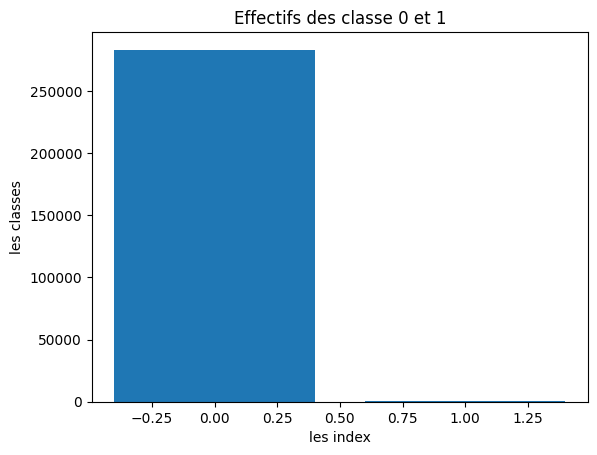

In [21]:
plt.bar(df_clean["Class"].value_counts().index, df_clean["Class"].value_counts().values)
plt.xlabel("les index")
plt.ylabel("les classes")
plt.title("Effectifs des classe 0 et 1")

plt.show()

In [22]:
df_clean["Amount"].describe()

,Amount
count,283726.000000
mean,88.472687
std,250.399437
min,0.000000
25%,5.600000
50%,22.000000
75%,77.510000
max,25691.160000


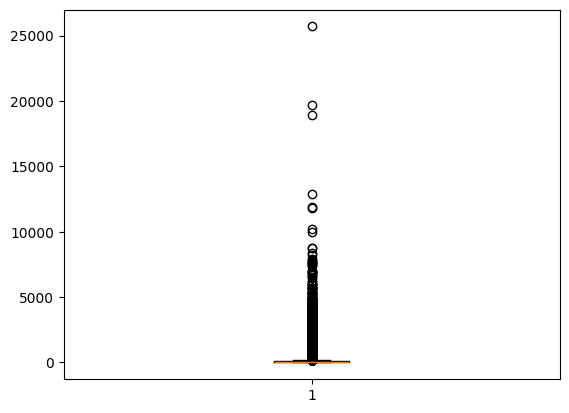

In [23]:
plt.boxplot(df_clean['Amount'])
plt.show()

In [24]:
df_clean.groupby("Class")['Amount'].mean()

,Amount
Class,
0,88.413575
1,123.871860


In [25]:
df_clean.groupby('Class')['Amount'].median()

,Amount
Class,
0,22.00
1,9.82


In [26]:
df_clean.groupby('Class')['Amount'].max()

,Amount
Class,
0,25691.16
1,2125.87


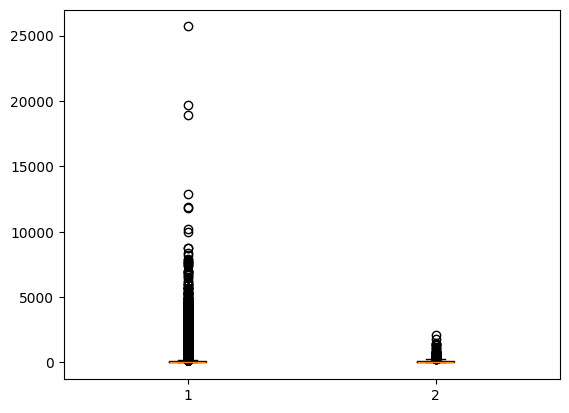

In [27]:
plt.boxplot([df_clean[df_clean['Class']== 0]['Amount'], df_clean[df_clean['Class']== 1]['Amount']])
plt.show()

In [28]:
df_clean[(df_clean['Class']== 1) & (df_clean['Amount']> 1000)].shape

(9, 31)

In [29]:
y = df_clean["Class"]

In [30]:
X= df_clean.drop( columns="Class")

In [31]:
X.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99


In [32]:
X.shape

(283726, 30)

In [33]:
y.shape

(283726,)

In [34]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state=42, stratify=y)

In [35]:
X_train.shape
X_test.shape
y_train.shape
y_test.shape

(56746,)

In [36]:
y_train.value_counts()

,count
Class,
0,226602
1,378


In [37]:
y_test.value_counts()

,count
Class,
0,56651
1,95


In [38]:
scacler = StandardScaler()

In [39]:
X_train_scaler = scacler.fit_transform(X_train)
X_test_sclaer = scacler.transform(X_test)

In [40]:
model_Lr = LogisticRegression()

In [41]:
model_Lr.fit(X_train_scaler, y_train)

LogisticRegression()

In [42]:
y_pred_Lr = model_Lr.predict(X_test_sclaer)

In [43]:
cm = confusion_matrix(y_test, y_pred_Lr)

In [44]:
print(cm)

[[56641    10]
 [   40    55]]


In [45]:
cr = classification_report(y_test, y_pred_Lr)

In [46]:
print(cr)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.85      0.58      0.69        95

    accuracy                           1.00     56746
   macro avg       0.92      0.79      0.84     56746
weighted avg       1.00      1.00      1.00     56746



In [47]:
model_lr_balanced = LogisticRegression(class_weight='balanced')

In [48]:
model_lr_balanced.fit(X_train_scaler, y_train)

LogisticRegression(class_weight='balanced')

In [49]:
y_pred_lr_balanced = model_lr_balanced.predict(X_test_sclaer)

In [50]:
cm_balanced = confusion_matrix(y_test, y_pred_lr_balanced)

In [51]:
print(cm_balanced)

[[55262  1389]
 [   12    83]]


In [52]:
cr_balanced = classification_report(y_test, y_pred_lr_balanced)

In [53]:
print(cr_balanced)

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746



In [54]:
proba = model_lr_balanced.predict_proba(X_test_sclaer)

In [55]:
print(proba)

[[0.97837355 0.02162645]
 [0.97992848 0.02007152]
 [0.98975977 0.01024023]
 ...
 [0.95881432 0.04118568]
 [0.95396833 0.04603167]
 [0.97310062 0.02689938]]


In [56]:
proba.shape

(56746, 2)

In [57]:
proba[:,1]

array([0.02162645, 0.02007152, 0.01024023, ..., 0.04118568, 0.04603167,
       0.02689938])

In [58]:
y_pred_07 = (proba[:, 1] >= 0.7).astype(int)

In [59]:
print(y_pred_07)

[0 0 0 ... 0 0 0]


In [60]:
cm_07 = confusion_matrix(y_test, y_pred_07)

In [61]:
print(cm_07)

[[56017   634]
 [   12    83]]


In [62]:
cr_07 = classification_report(y_test, y_pred_07)
print(cr_07)

              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56651
           1       0.12      0.87      0.20        95

    accuracy                           0.99     56746
   macro avg       0.56      0.93      0.60     56746
weighted avg       1.00      0.99      0.99     56746



In [63]:
y_pred09 = (proba[:,1]>= 0.9).astype(int)
cm_09 = confusion_matrix(y_test, y_pred09)
cr_09 = classification_report(y_test, y_pred09)

print(cr_09)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.26      0.83      0.40        95

    accuracy                           1.00     56746
   macro avg       0.63      0.91      0.70     56746
weighted avg       1.00      1.00      1.00     56746



In [64]:
print(cm_09)

[[56429   222]
 [   16    79]]


In [65]:
y_pred08 = (proba[:,1]>= 0.8).astype(int)
cm_08 = confusion_matrix(y_test, y_pred08)
cr_08 = classification_report(y_test,y_pred08)

print(cr_08)
print(cm_08)

              precision    recall  f1-score   support

           0       1.00      0.99      1.00     56651
           1       0.16      0.84      0.27        95

    accuracy                           0.99     56746
   macro avg       0.58      0.92      0.63     56746
weighted avg       1.00      0.99      0.99     56746

[[56232   419]
 [   15    80]]


In [71]:
model_rf = RandomForestClassifier(n_estimators = 100, random_state = 42)

In [72]:
model_rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [75]:
y_pred_rf = model_rf.predict(X_test)

cr_rf = classification_report(y_test, y_pred_rf)
print(cr_rf)
cm_rf = confusion_matrix(y_test, y_pred_rf)
print(cm_rf)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.97      0.73      0.83        95

    accuracy                           1.00     56746
   macro avg       0.99      0.86      0.92     56746
weighted avg       1.00      1.00      1.00     56746

[[56649     2]
 [   26    69]]


In [76]:
proba_rf = model_rf.predict_proba(X_test)

In [77]:
y_pred_rf03 = (proba_rf[:,1]>=0.3).astype(int)

cr_rf03 = classification_report(y_test, y_pred_rf03)
cm_rf03 = confusion_matrix(y_test, y_pred_rf03)

print(cr_rf03)
print(cm_rf03)


              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.92      0.77      0.84        95

    accuracy                           1.00     56746
   macro avg       0.96      0.88      0.92     56746
weighted avg       1.00      1.00      1.00     56746

[[56645     6]
 [   22    73]]


In [86]:
X_train_new, X_val, y_train_new, y_val = train_test_split(X_train, y_train, random_state=42, test_size = 0.2, stratify = y_train)

In [87]:
y_train_new.value_counts(normalize=True)

,proportion
Class,
0,0.998337
1,0.001663


In [88]:
y_val.value_counts(normalize= True)

,proportion
Class,
0,0.998326
1,0.001674


In [89]:
X_train_new_scaler = scacler.fit_transform(X_train_new)

In [84]:
X_val_scaler = scacler.transform(X_val)

In [92]:
model_lr_val = LogisticRegression(class_weight="balanced", max_iter= 1000, random_state=42)

model_lr_val.fit(X_train_new_scaler, y_train_new)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [93]:
proba_val = model_lr_val.predict_proba(X_val_scaler)

In [95]:
y_pred_val07 = (proba_val[:,1] >= 0.7).astype(int)

In [96]:
print(confusion_matrix(y_val, y_pred_val07))

[[44735   585]
 [    8    68]]


In [97]:
print(classification_report(y_val, y_pred_val07))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99     45320
           1       0.10      0.89      0.19        76

    accuracy                           0.99     45396
   macro avg       0.55      0.94      0.59     45396
weighted avg       1.00      0.99      0.99     45396



In [99]:
y_pred_val09 = (proba_val[:,1] >= 0.9).astype(int)
print(confusion_matrix(y_val, y_pred_val09))
print(classification_report(y_val, y_pred_val09))


[[45110   210]
 [   10    66]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     45320
           1       0.24      0.87      0.38        76

    accuracy                           1.00     45396
   macro avg       0.62      0.93      0.69     45396
weighted avg       1.00      1.00      1.00     45396



In [142]:
cm = confusion_matrix(y_val, y_pred_val07)
fn =cm[1,0]
fp = cm[0,1]
def calcul_cout(fn, fp):
  return (fn *1000) + (fp * 20)

calcul_cout(fn, fp)


np.int64(19700)

In [177]:
meilleur_cout = float("inf")
seuils = np.arange(0.90, 1, step = 0.01 )
for seuil in seuils:
  y_pred_seuil = (proba_val[:,1] >= seuil).astype(int)
  cm_seuil = confusion_matrix(y_val, y_pred_seuil)
  cout = (calcul_cout(cm_seuil[1,0], cm_seuil[0,1]))

  recall = cm_seuil[1,1] / (cm_seuil[1,1] + cm_seuil[1,0])
  if recall >= 0.85:
    if cout < meilleur_cout:
      meilleur_cout = cout
      meilleur_seuil = seuil
      cm_meilleur_seuil = cm_seuil
print(meilleur_seuil)
print(meilleur_cout)
print(f"Matrice de confusion du seuil {meilleur_seuil} :")
print( cm_meilleur_seuil)


0.9800000000000001
11140
Matrice de confusion du seuil 0.9800000000000001 :
[[45263    57]
 [   10    66]]


In [179]:
proba_train = model_lr_val.predict_proba(X_train_new_scaler)

In [184]:
X_train_pred = (proba_train[:,1] >= 0.98).astype(int)
cm_x_train = confusion_matrix(y_train_new, X_train_pred)
cr_x_train = classification_report(y_train_new, X_train_pred)
print(cm_x_train)
print(cr_x_train)

[[181023    259]
 [    43    259]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    181282
           1       0.50      0.86      0.63       302

    accuracy                           1.00    181584
   macro avg       0.75      0.93      0.82    181584
weighted avg       1.00      1.00      1.00    181584



In [189]:
propa_meilleur_seuil_test = proba_train = model_lr_val.predict_proba(X_test_sclaer)

In [191]:
y_pred_meilleur_seuil = (propa_meilleur_seuil_test[:,1] >= meilleur_seuil).astype(int)
cm_meilleur_seuil= confusion_matrix(y_test, y_pred_meilleur_seuil)
cr_meilleur_seuil = classification_report(y_test, y_pred_meilleur_seuil)
print(cm_meilleur_seuil)
print(cr_meilleur_seuil)

[[56585    66]
 [   19    76]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.54      0.80      0.64        95

    accuracy                           1.00     56746
   macro avg       0.77      0.90      0.82     56746
weighted avg       1.00      1.00      1.00     56746



In [194]:
smote = SMOTE(random_state = 42)

In [196]:
X_train_smote, y_train_smote = smote.fit_resample(X_train_new_scaler, y_train_new)

In [199]:
y_train_smote.value_counts()

,count
Class,
0,181282
1,181282


In [200]:
model_lr_smote = LogisticRegression(max_iter =1000, random_state= 42)

In [202]:
model_lr_smote.fit(X_train_smote, y_train_smote)

LogisticRegression(max_iter=1000, random_state=42)

In [203]:
y_pred_smote_val = model_lr_smote.predict(X_val_scaler)

In [205]:
cm_smote_val = confusion_matrix(y_val, y_pred_smote_val)
print(cm_smote_val)

[[44031  1289]
 [    7    69]]


In [207]:
cr_smote_val = classification_report(y_val, y_pred_smote_val)
print(cr_smote_val)

              precision    recall  f1-score   support

           0       1.00      0.97      0.99     45320
           1       0.05      0.91      0.10        76

    accuracy                           0.97     45396
   macro avg       0.53      0.94      0.54     45396
weighted avg       1.00      0.97      0.98     45396



In [208]:
proba_smote_val = model_lr_smote.predict_proba(X_val_scaler)

In [214]:
meilleur_cout_smote = float("inf")
seuil_smote = np.arange(0.90, 1, step = 0.01 )
for seuil in seuil_smote:
  y_pred_seuil_smote = (proba_fraude_smote >= seuil).astype(int)
  cm_seuil_smote = confusion_matrix(y_val, y_pred_seuil_smote)
  cout_smote = (calcul_cout(cm_seuil_smote[1,0], cm_seuil_smote[0,1]))

  recall_smote = cm_seuil_smote[1,1] / (cm_seuil_smote[1,1] + cm_seuil_smote[1,0])
  if recall_smote >= 0.85:
    if cout_smote < meilleur_cout_smote:
      meilleur_cout_smote = cout_smote
      meilleur_seuil_smote = seuil
      cm_meilleur_seuil_smote = cm_seuil_smote
print(meilleur_seuil_smote)
print(meilleur_cout_smote)
print(f"Matrice de confusion du seuil {meilleur_seuil_smote} :")
print( cm_meilleur_seuil_smote)

0.9900000000000001
11080
Matrice de confusion du seuil 0.9900000000000001 :
[[45266    54]
 [   10    66]]


In [216]:
proba_test_smote = model_lr_smote.predict_proba(X_test_sclaer)[:, 1]

seuil_final = 0.99

y_pred_test_smote = (proba_test_smote >= seuil_final).astype(int)

cm_test_smote = confusion_matrix(y_test, y_pred_test_smote)

tn = cm_test_smote[0, 0]
fp = cm_test_smote[0, 1]
fn = cm_test_smote[1, 0]
tp = cm_test_smote[1, 1]

cout_test_smote = calcul_cout(fn, fp)

print("Matrice de confusion :")
print(cm_test_smote)

print("\nRapport de classification :")
print(classification_report(y_test, y_pred_test_smote))

print(f"\nCoût total : {cout_test_smote} €")
print(f"Fraudes détectées : {tp}")
print(f"Fraudes manquées : {fn}")
print(f"Fausses alertes : {fp}")

Matrice de confusion :
[[56591    60]
 [   20    75]]

Rapport de classification :
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.56      0.79      0.65        95

    accuracy                           1.00     56746
   macro avg       0.78      0.89      0.83     56746
weighted avg       1.00      1.00      1.00     56746


Coût total : 21200 €
Fraudes détectées : 75
Fraudes manquées : 20
Fausses alertes : 60
